# Matching Process Trees from ACME4 dataset -- Experiments

The ACME4 data tables used in this notebook can be downloaded from: https://gdo168.llnl.gov/data/ACME4/stdview-20240819-20240923/


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
from collections import Counter
import igraph as ig
import gzip
import pickle
from functools import partial
from scipy.spatial import distance
import time
import umap 
import random
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay #, precision_score, recall_score,  roc_curve, auc
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import HDBSCAN
import partition_igraph
from sklearn.metrics import adjusted_mutual_info_score as AMI
import seaborn as sns

## our matching algorithm
import sys
import os
sys.path.insert(0,os.path.abspath('../Matching'))
import igraph_io as igio
import fast_match as fm  ## fast version
import needleman_wunsch_tree as nwt ## slower, more flexibility for scoring functions

## several utility functions
from acme_util import *

# 2. Applique les 300 DPI par défaut à TOUS les futurs plt.savefig()
plt.rcParams['savefig.dpi'] = 300

# 3. Optionnel mais recommandé : ajuste automatiquement les bordures pour éviter les textes coupés
plt.rcParams['savefig.bbox'] = 'tight'


# Build process trees from the ```process_uber_summary``` table

### Build graph $G$ and find the connected components (process trees)
1. From the ```process_uber_summary``` table, build an ```igraph``` directed graph $G$ where each edge is of the form: ```parent PID --> child PID```
2. Get all (weak) connected components from $G$ -- those are the ```process trees``` (with one exception where a loop is present, which we drop), and save those in the **Trees** object
    * 99.98% of components are of size 2 (1,111,052  out of 1,111,278) ...
    * 224 process trees contain between 3 and 50k nodes
    * 1 has more then 250k nodes


In [2]:
process_summary = pd.read_parquet("Data/process_uber_summary.parquet", columns=['pid_hash', 'parent_pid_hash', 'process_name', 'user_name', 'red_team'] )
process_summary.head()


,pid_hash,parent_pid_hash,process_name,user_name,red_team
0,A86DB324303BBC24B4C279909AC5AD00,B066C89E8047845304C38E8BEE22AD90,powershell.exe,ACME\user10,1
1,C194ECED319F84EC8DAED02EE44FCE63,450735D5CC2CCEC4C8B12EC8818120E8,wmic.exe,None,0
2,FA50BB30E957D73120420F46B18AE167,450735D5CC2CCEC4C8B12EC8818120E8,wmic.exe,None,0
3,5803C60CEB8387DFA7ADA3E5E75E88FF,6FB634509A57999E72BCAFA74A8FFF29,wmic.exe,None,0
4,3BD26DAC90333D99453E9F506A514B1B,6FB634509A57999E72BCAFA74A8FFF29,wmic.exe,None,0


In [3]:
## we'll use those throughout for quick reference
dct_username = dict(zip(process_summary.pid_hash,process_summary.user_name))
dct_label = dict(zip(process_summary.pid_hash,process_summary.red_team))
dct_processname = dict(zip(process_summary.pid_hash,process_summary.process_name))


In [4]:
%%time
Trees = extract_process_trees(process=process_summary, uid='pid_hash', parent_uid='parent_pid_hash',
                              min_tree_size=2, max_tree_size=1000000, 
                              extra={'process_name':'process','user_name':'user','red_team':'redteam'})


CPU times: user 15.7 s, sys: 519 ms, total: 16.2 s
Wall time: 16.2 s


In [5]:
## total number of trees -- most are of size 2
print('number of trees:',len(Trees))
Counter(Trees.membership).most_common(10)


number of trees: 1111277


[(5, 257744),
 (4, 33070),
 (2, 28780),
 (1, 26599),
 (3, 24610),
 (0, 23835),
 (746, 20852),
 (745, 20350),
 (751, 18940),
 (744, 18784)]

In [6]:
## large CC - all processes are non redteam
Counter(Trees.subgraph(5).vs['redteam'])

Counter({0: 257744})

In [ ]:
%%time
## reload -- exclude size-2 trees and giant one
Trees = extract_process_trees(process=process_summary, uid='pid_hash', parent_uid='parent_pid_hash',
                              min_tree_size=3, max_tree_size=50000, 
                              extra={'process_name':'process','user_name':'user','red_team':'redteam'})


In [ ]:
## for plotting - red_team nodes in red other in black
Trees.graph.vs['label_color'] = 'black'
Trees.graph.vs['color'] = 'black'
for v in Trees.graph.vs:
    if dct_label.get(v['uid'],0)>0:
        v['label_color']='red'
        v['color']='red'

# EDA

In [ ]:
print('number of trees:',len(Trees))
plt.hist([np.log2(x) for x in Trees.sizes()])
plt.xlabel('log2 (tree size)', fontsize=14);


In [ ]:
## those are the attributes for each node in graph G
Trees.graph.vs[0]

### List all subtrees with known root process name

There are 3 'bad' usernames which we mark in columns 'bad3' , 'bad9' and 'bad25'.


In [ ]:
df_trees = pd.DataFrame()
for t in range(len(Trees)):
    _df = acme_list_process_subtrees(Trees.subgraph(t), dct_username, dct_label)
    _df.insert(loc=0, column='tree', value=t)
    df_trees = pd.concat([df_trees,_df])
df_trees.head(5)


In [ ]:
print('min tree size:',min(df_trees.nodes), 'max:', max(df_trees.nodes))
print('trees with some redteam nodes:',Counter(df_trees.redteam>0))


In [ ]:
## pick a tree for plotting as illustration
df_trees[ (df_trees.layers==5) & (df_trees.redteam>0) & (df_trees.nodes==10) ]

In [ ]:
sg = acme_get_bfs_subtree(Trees, 2, 12347)
fig, ax = plt.subplots(figsize=(15, 10))
ig.plot(sg, target=ax, layout=sg.layout_reingold_tilford(), 
       vertex_label=sg.vs['process'], vertex_label_size=15, 
       vertex_size=1, edge_color='lightgrey', edge_arrow_size=0)
ax.invert_yaxis()
ax.margins(x=.1)
#plt.savefig('process_tree_example.png')

# Experiment #1 -  top hits using various weight functions with the matching algorithm

* we select deep trees with up to 500 nodes (not too big, for display purpose)
* we compare all "red trees" (with some redteam label) to all "black trees"
* (optional) we report matches with at least one redteam label on the red tree matching path

We define different weight functions:

* **default**: exact match (between process names)
* **redblack**: exact match but only between redteam and non-readteam processes
* **invfreq**: exact match weighted by each process' inverse frequency (on log scale)
* **embed**: exact match weighted by the process' distance in embedded space (built from numerical features via ecdf)


In [ ]:
## extract the subtrees
_df = df_trees[ (df_trees.layers>=7) & (df_trees.nodes<=200) ]
_trees = _df.tree.tolist()
_roots = _df.root.tolist()
TreeData_label = np.array(_df.redteam>0)
TreeData = []
dct_motifs = {} ## used in #1(e)
for (t,r) in zip(_trees,_roots):
    sg = acme_get_bfs_subtree(Trees, t, r) 
    sg = acme_add_motifs(sg) ## add the motifs
    dct_motifs |= dict(zip(sg.vs['uid'], sg.vs['motifs']))
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='uid'))
Counter(TreeData_label)


### experiment #1(a) -- default weight

This is the default with a binary score of 1 if the process names coincide, 0 otherwise.


In [ ]:
## default weights
def _def(a, b, _process):
    return int(_process[a]==_process[b])
weight = partial(_def, _process=dct_processname)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)

## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0.2,0))
#plt.savefig('weight_default.png', pad_inches=0)
print('Score:',match.score,'Sizes:',sg_red.vcount(),sg_black.vcount())


### experiment #1(b) -- redblack weight

A binary score of 1 if the process names coincide AND the labels (here, 'redteam') are different, 0 otherwise.


In [ ]:
## redblack
def _rb(a, b, _process, _label):
    return int(_process[a]==_process[b])*(_label[a]!=_label[b])
weight = partial(_rb, _process=dct_processname, _label=dct_label)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)

## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
#plt.savefig('weight_redblack.png', pad_inches=0)
print('Score:',match.score,'Sizes:',sg_red.vcount(),sg_black.vcount())


### experiment #1(c) -- inverse fequency weight

A score in (0,1] inversely proportional (on log scale) to the process frequency if the process names coincide; 0 otherwise.


In [ ]:
## inverse frequency
proc_counts = Counter([dct_processname.get(v,'') for v in Trees.graph.vs['uid']])
dct_invfreq = {k: float(1/np.log2(v+1)) for k, v in proc_counts.items()} ## max score of 1 when v==1
def _if(a, b, _process, _freq):
    return int(_process[a]==_process[b])*(_freq[_process[a]])
weight = partial(_if, _process=dct_processname, _freq=dct_invfreq)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)

## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
#plt.savefig('weight_invfreq.png', pad_inches=0)
print('Score:',match.score,'Sizes:',sg_red.vcount(),sg_black.vcount())


In [ ]:
## at least one of the processes above is very rare in our dataset
sum([x == 'vs_setup_bootstrapper.exe' for x in Trees.graph.vs['process']])


### experiment #1(d) -- embedded weight

The ecdf-based embedding is computed in a different notebook and is stored into multiple files in the 'Data/' directory.
To merge into a single file, run:

```cat Data/acme4_process_num_features_embedding_ecdf.pkl.gz.* | gunzip > Data/acme4_process_num_features_embedding_ecdf.pkl.gz```

The embedded weight: a score in (0,1] inversely proportional to the PID's Manhattan distance in embedded space if the process names coincide, 0 otherwise.


Score: 7.826830863952637 Sizes: 200 161


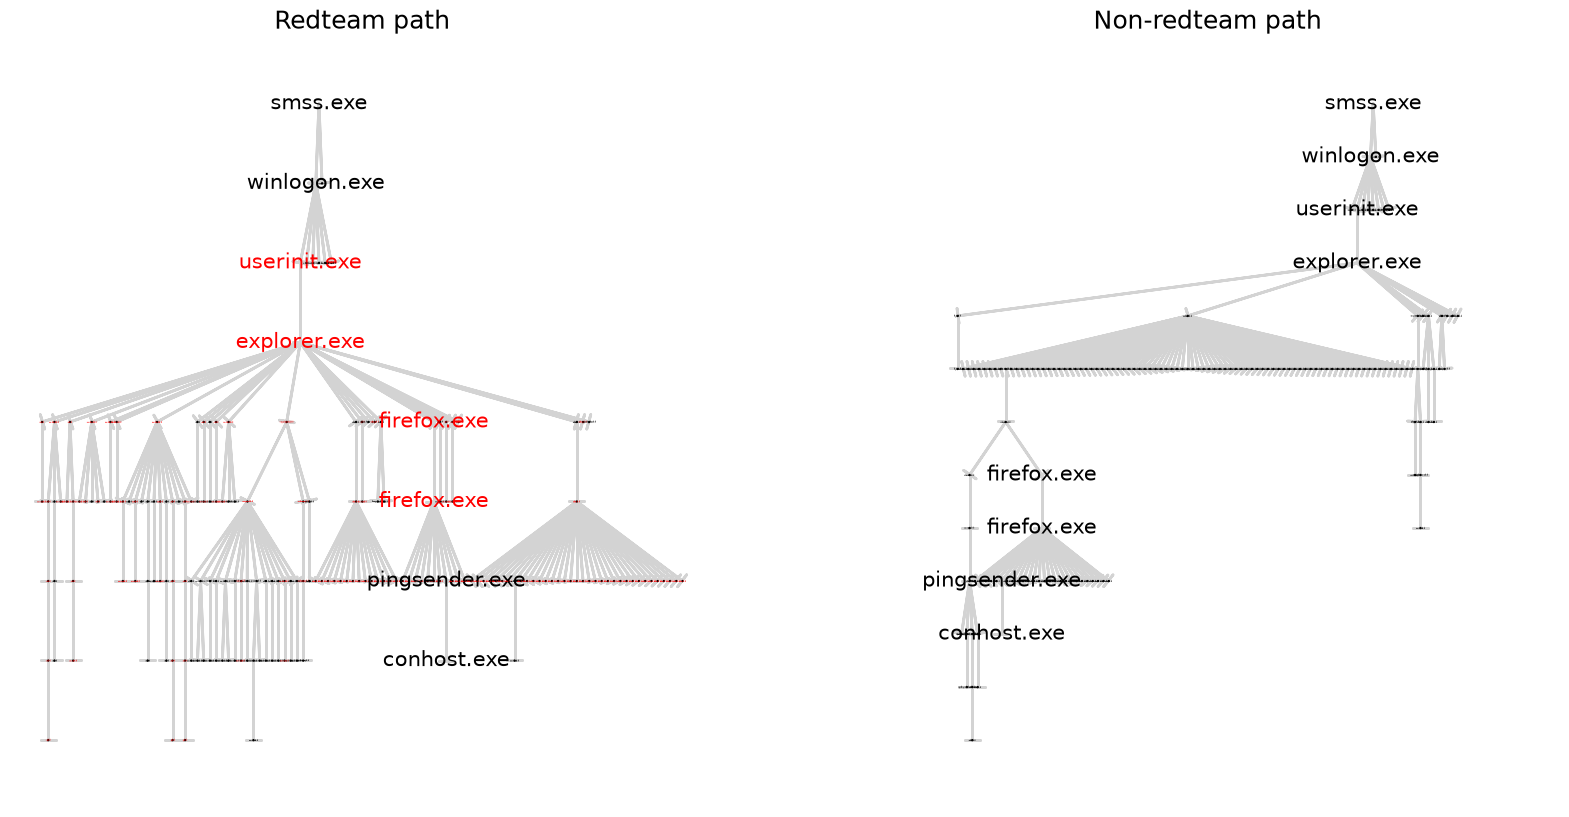

In [20]:
# embedded space
with gzip.open('Data/acme4_process_num_features_embedding_ecdf.pkl.gz', 'rb') as fp:
    embedding_ecdf = pickle.load(fp)
dim = len(next(iter(embedding_ecdf.values())))
def _es(a, b, _process, _emb):
    return int(_process[a]==_process[b])*(1-distance.cityblock(_emb[a],_emb[b])/dim)
    #return (1-distance.cityblock(_emb[a],_emb[b])/dim)
weight = partial(_es, _process=dct_processname, _emb=embedding_ecdf)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)

## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.14))
#plt.savefig('weight_embed.png', pad_inches=0)
print('Score:',match.score,'Sizes:',sg_red.vcount(),sg_black.vcount())


#### Plot in Embed space

We look at PID's embeddings for the matching paths for the red and black trees. We refer to each position in the path from 0 to 7, with red and black color respectively.


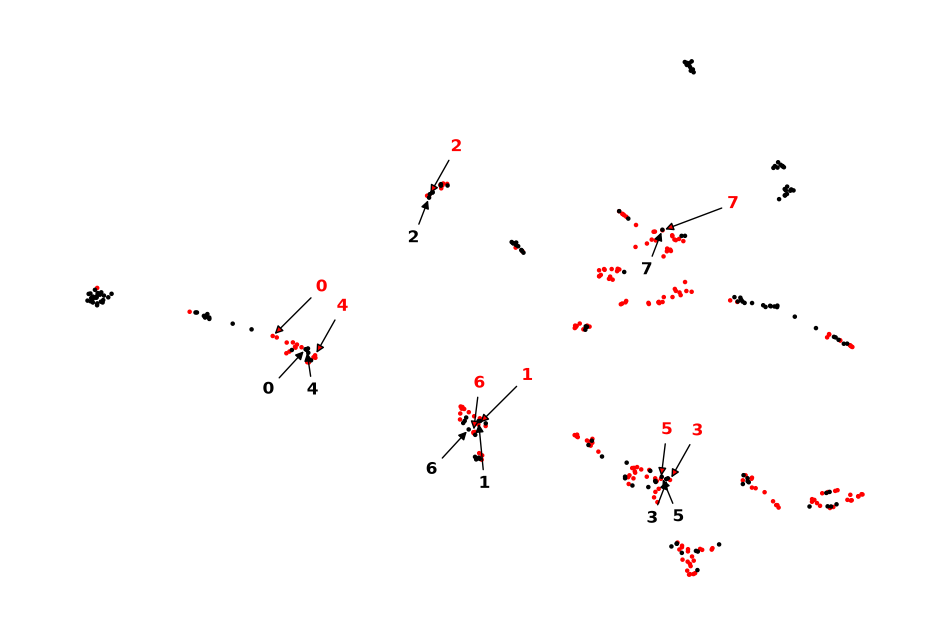

In [21]:
## some trial and error to get nice positions
angles = np.linspace(0, 2 * np.pi, 16, endpoint=False)
offx = 3*np.cos(angles)
offy = 3*np.sin(angles)
offx = 2*np.array([1,1,.5,.5,.5,0,0,1.5,-1,0,-.5,-.5,0,.25,-1,-.5])
offy = 3*np.array([1,1,1,1,1,1,1,.5,-1,-1.5,-1,-1,-1,-1,-1,-1])

## the paths
path = [x[0] for x in match.path_internal]
l = len(path)
s = np.tile(np.arange(l),2)
cl = np.repeat(['red','black'],l)
l = sg_red.vcount()
path.extend([x[1]+l for x in match.path_internal])

## red and black trees - map to 2D for viz
X = [embedding_ecdf[x] for x in sg_red.vs['uid']]
X.extend([embedding_ecdf[x] for x in sg_black.vs['uid']])
c = np.concatenate( [np.repeat('red',sg_red.vcount()), np.repeat('black',sg_black.vcount())] )
reducer = umap.UMAP(n_neighbors=7, metric='manhattan', min_dist=.25, spread=1.5, n_jobs=1, random_state=123)
embedding = reducer.fit_transform(np.array(X))

## plot and annotate
fig, ax = plt.subplots(figsize=(12,8))
ax.scatter(embedding[:, 0], embedding[:, 1], s=5, c=c );
for i in range(len(path)):
    ax.annotate(
        s[i],       
        xy=(embedding[path[i], 0], embedding[path[i], 1]), # arrow's
        xytext=(embedding[path[i], 0] + offx[i], embedding[path[i], 1] + offy[i]), # text
        arrowprops=dict(
            facecolor=cl[i], # arrow's
            arrowstyle="-|>", 
            lw=1.0           # line width
        ),
        fontsize=12,
        color=cl[i],
        fontweight="bold"
    )
ax.margins(.1)
plt.axis('off');
#plt.savefig('map_embed.png', pad_inches=0)


### experiment #1(e) -- motifs

For each node v, we consider the subtree with v taken as the root. We count the number of processes in this subtree coupled with their depth.
For each node, this is stored as a dictionary of motifs with entries of the form: {("process name",depth):count}.

For the similarity score between two nodes, we use the following weight function. For each matching ("process name",depth) with respective counts c1, c2 we add 1-exp(-min(c1, c2)) to the score.
We normalize the score by dividing by the size of the smallest dictionary (smallest number of entries).

This yields matching paths with similar structure under the corresponding nodes in the path.


In [22]:
def _ms(a, b, _process, _motifs):
    x = _motifs[a]
    y = _motifs[b]
    _s = 0
    for  idx, (key, val) in enumerate(x.items()):
        _s += (1-np.exp(-min(val, y.get(key,0))))
    
    _s /= max(1,min(len(x),len(y)))        
    return int(_process[a]==_process[b])*(_s)
weight = partial(_ms, _process=dct_processname, _motifs=dct_motifs)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


Score: 3.7927234172821045 Sizes: 106 15


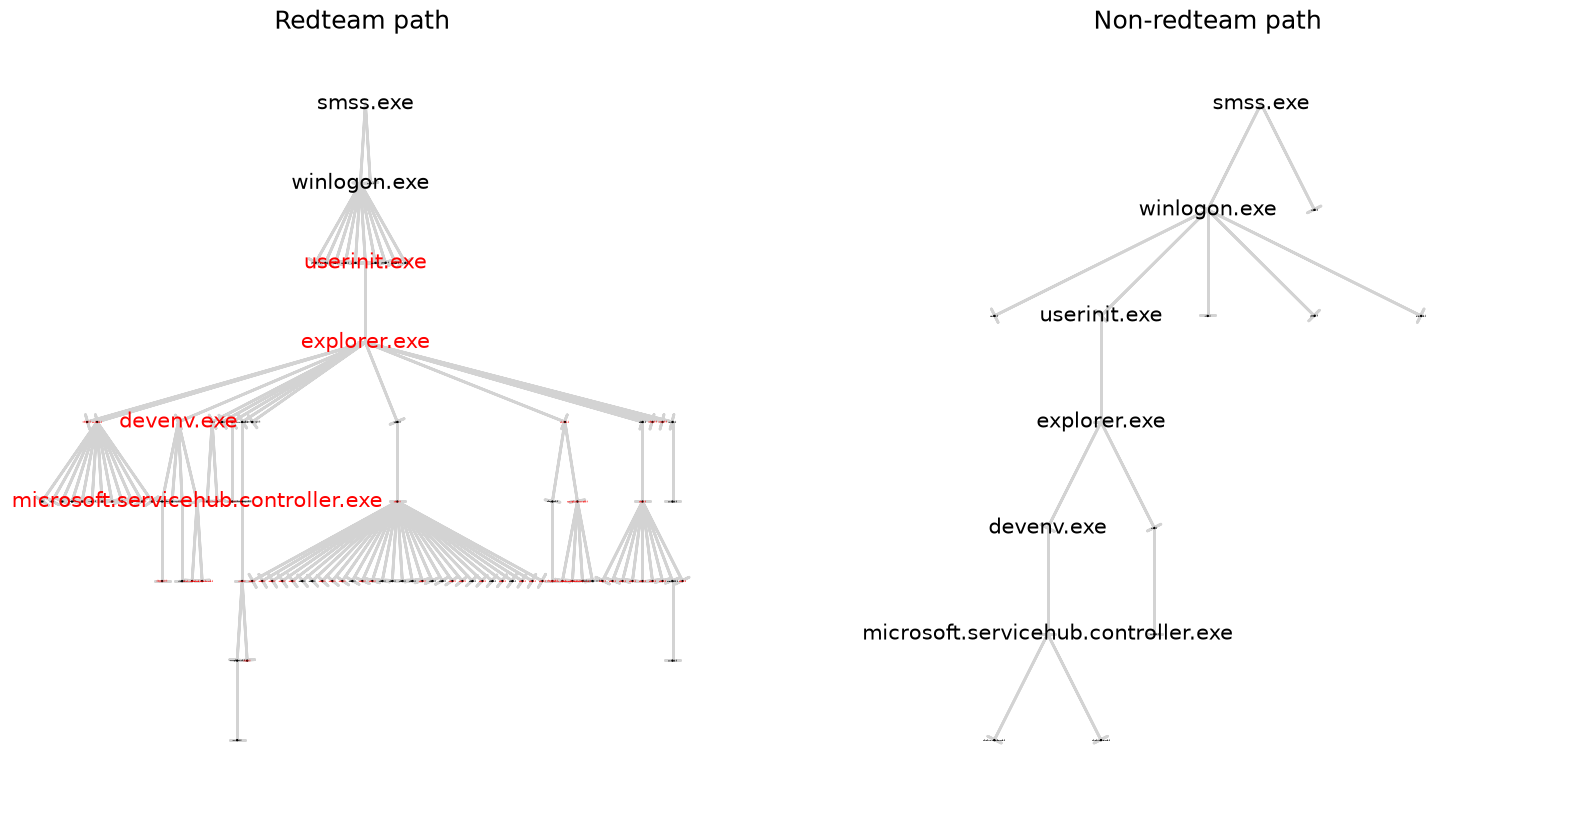

In [23]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.25))
#plt.savefig('weight_motifs.png', pad_inches=0)
print('Score:',match.score,'Sizes:',sg_red.vcount(),sg_black.vcount())


In [24]:
## level 1 processes : same
print('level 1:')
V, L, P = sg_black.bfs(0)
print('black tree:',np.sort([sg_black.vs[v]['process'] for v in V[L[1]:L[2]]]))
V, L, P = sg_red.bfs(0)
print('red tree:', np.sort([sg_red.vs[v]['process'] for v in V[L[1]:L[2]]]))

## level 2 processes : same
print('\nlevel 2:')
V, L, P = sg_black.bfs(0)
print('black tree:',np.sort([sg_black.vs[v]['process'] for v in V[L[2]:L[3]]]))
V, L, P = sg_red.bfs(0)
print('red tree:', np.sort([sg_red.vs[v]['process'] for v in V[L[2]:L[3]]]))

## level 4 processes under explorer.exe
msc = match.path_internal[3]
print('\nlevel 4 under explorer.exe:')
V, L, P = sg_black.bfs(msc[1])
print('black tree:',np.sort([sg_black.vs[v]['process'] for v in V[L[1]:L[2]]]))
V, L, P = sg_red.bfs(msc[0])
print('red tree:', np.sort([sg_red.vs[v]['process'] for v in V[L[1]:L[2]]]))

## un-named processes at level 4&5 under explorer in black tree
print('\nlevel 4&5 under explorer.exe:')
print('black tree:',sg_black.vs[10]['process'],sg_black.vs[12]['process'])
print('red tree:',sg_red.vs[17]['process'], [sg_red.vs[i]['process'] for i in sg_red.neighbors(17,'out')])

## level 6 processes under microsoft.servicehub.controller.exe
msc = match.path_internal[5]
print('\nlevel 6 under microsoft.servicehub.controller.exe:')
V, L, P = sg_black.bfs(msc[1])
print('black tree:',np.sort([sg_black.vs[v]['process'] for v in V[L[1]:L[2]]]))
V, L, P = sg_red.bfs(msc[0])
print('red tree:', np.sort([sg_red.vs[v]['process'] for v in V[L[1]:L[2]]]))


level 1:
black tree: ['csrss.exe' 'winlogon.exe']
red tree: ['csrss.exe' 'winlogon.exe']

level 2:
black tree: ['atbroker.exe' 'dwm.exe' 'fontdrvhost.exe' 'logonui.exe' 'userinit.exe']
red tree: ['atbroker.exe' 'atbroker.exe' 'dwm.exe' 'fontdrvhost.exe' 'logonui.exe'
 'logonui.exe' 'logonui.exe' 'logonui.exe' 'userinit.exe' 'wlrmdr.exe']

level 4 under explorer.exe:
black tree: ['cmd.exe' 'devenv.exe']
red tree: ['cmd.exe' 'control.exe' 'devenv.exe' 'devenv.exe' 'firefox.exe'
 'firefox.exe' 'notepad.exe' 'notepad.exe' 'powershell.exe'
 'powershell.exe' 'securityhealthsystray.exe' 'ubuntu.exe'
 'vs_buildtools.exe' 'wordpad.exe']

level 4&5 under explorer.exe:
black tree: cmd.exe conhost.exe
red tree: cmd.exe ['conhost.exe', 'ec2launch.exe']

level 6 under microsoft.servicehub.controller.exe:
black tree: ['servicehub.identityhost.exe' 'servicehub.vsdetouredhost.exe']
red tree: ['servicehub.identityhost.exe' 'servicehub.vsdetouredhost.exe']


In [25]:
sg.vs[0]['motifs']

{('explorer.exe', 1): 1,
 ('cmd.exe', 2): 1,
 ('conhost.exe', 3): 1,
 ('python.exe', 3): 1,
 ('cmd.exe', 4): 1,
 ('py.exe', 5): 1,
 ('python.exe', 6): 1,
 ('python.exe', 7): 1}

In [26]:
## another option
def _ms2(a, b, _process, _motifs):
    x = _motifs[a]
    y = _motifs[b]
    _s = 0
    for  idx, (key, val) in enumerate(x.items()):
        _s += min(val, y.get(key,0))
    if _s>0:
        _s /= min(sum(x.values()),sum(y.values()))
    return int(_process[a]==_process[b])*(_s)
weight = partial(_ms2, _process=dct_processname, _motifs=dct_motifs)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)


Score: 6.0 Sizes: 106 15


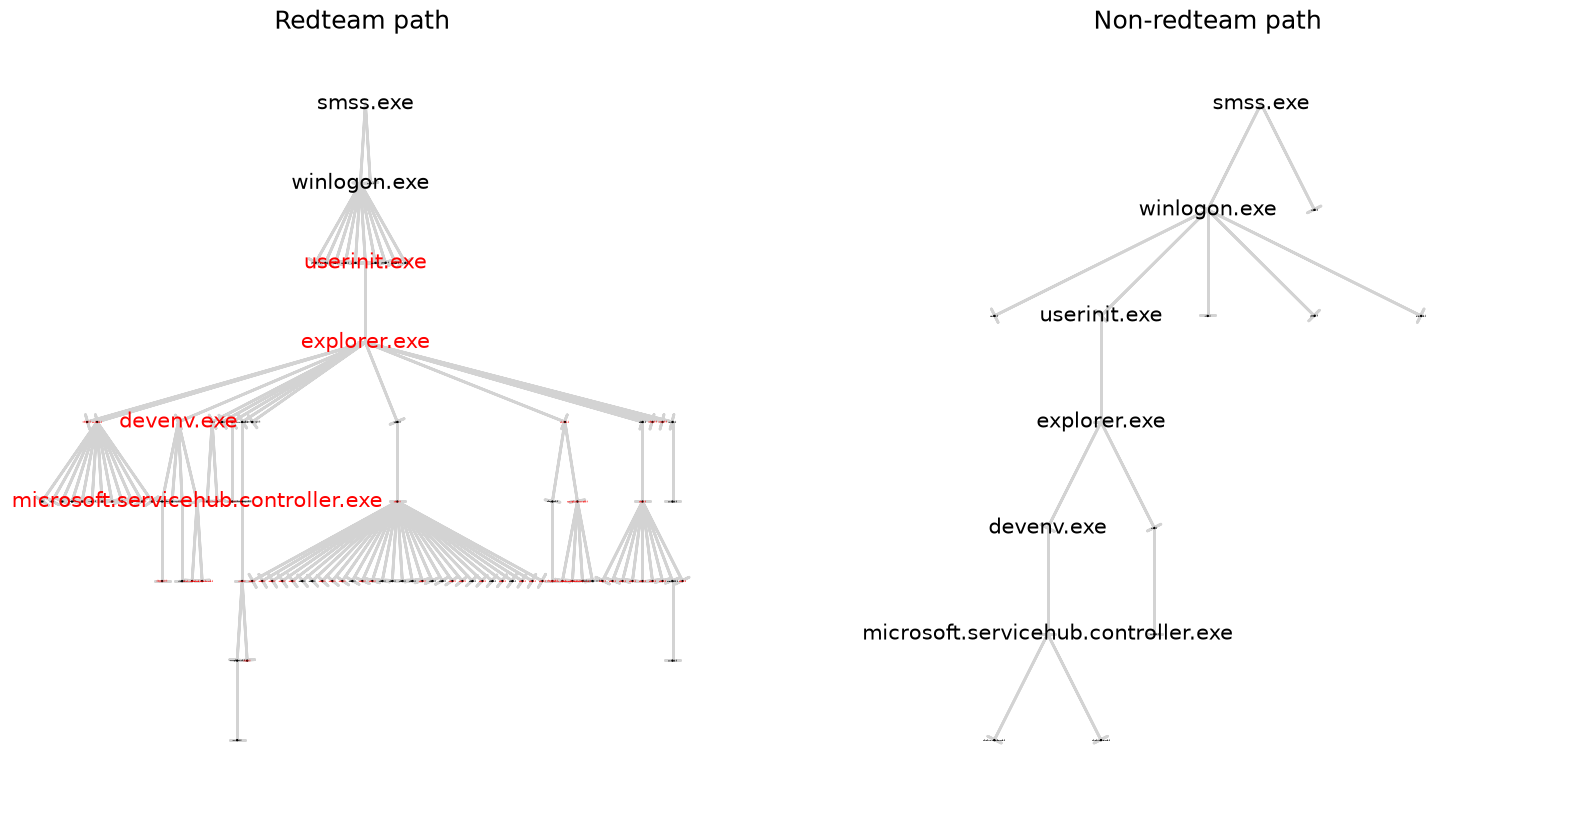

In [27]:
## plot best result
sg_red = acme_get_bfs_subtree(Trees, _trees[best_pair[0]], _roots[best_pair[0]]) 
sg_black = acme_get_bfs_subtree(Trees, _trees[best_pair[1]], _roots[best_pair[1]]) 
_sg_red = igio.igraph_to_treedata(sg_red, phi_name='uid')
_sg_black = igio.igraph_to_treedata(sg_black, phi_name='uid')
match = nwt.align_trees_algorithm1(_sg_red, _sg_black, w=weight)
plot_path((sg_red,sg_black), match.path_internal, margin=(0,.25))
#plt.savefig('weight_motifs.png', pad_inches=0)
print('Score:',match.score,'Sizes:',sg_red.vcount(),sg_black.vcount())


# Experiment #2 - some timings for the matching algorithm

Using the default weights, we compare:
* the basic implementation as in experiment #1(a)
* a faster implementation (with some pre-processing)
  

### experiment #2(a) -- speedup from experiment #1(a)

- we run the matching algorithms 1000 times on the best scoring pair from experiment #1(a)


In [28]:
## go back to experiment (1a) - what speedup can we get with the fast method?
_df = df_trees[ (df_trees.layers>=7) & (df_trees.nodes<=500) ]
_trees = _df.tree.tolist()
_roots = _df.root.tolist()
TreeData_label = np.array(_df.redteam>0)
TreeData = []
for (t,r) in zip(_trees,_roots):
    sg = acme_get_bfs_subtree(Trees, t, r) 
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='uid'))

## default weights
def _def(a, b, _process):
    return int(_process[a]==_process[b])
weight = partial(_def, _process=dct_processname)
best_pair = run_redblack_match(TreeData, TreeData_label, weight, dct_label, min_red_nodes=1)
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## basic algorithm
a = time.time()
for _ in range(1000):
    match = nwt.align_trees_algorithm1(TreeData[best_pair[0]], TreeData[best_pair[1]], w=weight)
slow_alg = time.time()-a

## fast algorithm
a = time.time()
for _ in range(1000):
    paths, score = fast.predict_encoded(enc[best_pair[0]], enc[best_pair[1]])
fast_alg = time.time()-a

print('time for 1000 runs, slow algorithm:',slow_alg,'fast algorithm:',fast_alg,'speedup:',slow_alg/fast_alg)


time for 1000 runs, slow algorithm: 17.84905242919922 fast algorithm: 0.0723872184753418 speedup: 246.5774042040222


### experiment #2(b) timings for the fast method with varying number of trees

By varying the tree sizes, we get different number of tree pairs (still comparing redteam and non-redteam), but we also get trees with larger number of paths.

We compute the running time of the matching algorithm as a function of the number of weighted tree pairs we compare, where each tree weight is its number of leaves.


In [29]:
## quick utility function to benchmark
def run_redblack_match_fast(TreeData, _label, _leaves):
    fast = fm.FastTreePathMatcher()
    fast.fit_encoder(TreeData)
    enc = [fast.encode_tree(t) for t in TreeData]
    best_score = 0
    num_leaves_pairs = 0
    for red in np.where(_label==True)[0]:
        for black in np.where(_label==False)[0]:
            paths, score = fast.predict_encoded(enc[red], enc[black])
            num_leaves_pairs += (_leaves[red]*_leaves[black])
            if score > best_score:
                best_score = score
    return best_score, num_leaves_pairs
        
## extract the subtrees - vary the max number of nodes
BS = []
min_layers = 7
for nn in [100,500,1000,1500,2000,3500]:
    _df = df_trees[ (df_trees.layers>=min_layers) & (df_trees.nodes<=nn) ]
    _trees = _df.tree.tolist()
    _roots = _df.root.tolist()
    _leaves = _df.leaves.tolist()
    TreeData_label = np.array(_df.redteam>0)
    num_tree_pairs = ( sum(TreeData_label==False) * sum(TreeData_label) )
    
    ## fast implementation
    a = time.time()
    TreeData = []
    for (t,r) in zip(_trees,_roots):
        sg = acme_get_bfs_subtree(Trees, t, r) 
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
    fast_preproc = time.time()-a
    
    a = time.time()
    best_score, num_leaves_pairs = run_redblack_match_fast(TreeData, TreeData_label, _leaves)
    fast_alg = time.time()-a
    BS.append([num_tree_pairs, num_leaves_pairs, fast_preproc, fast_alg, best_score])
    # print(num_tree_pairs, num_leaves_pairs, fast_preproc, fast_alg, best_score) ## debug
_BS = pd.DataFrame(BS, columns=['tree pairs','weighted tree pairs (leaves)','pre-processing','runtime','best score'])
_BS


,tree pairs,weighted tree pairs (leaves),pre-processing,runtime,best score
0,480,300736,3.692724,0.016289,6.0
1,4608,65269422,13.324776,0.409344,9.0
2,7238,266953316,34.346483,1.559004,12.0
3,7850,386313972,38.803648,2.084334,12.0
4,8580,749315920,67.011619,3.514092,13.0
5,8745,844612314,67.124898,3.871950,13.0


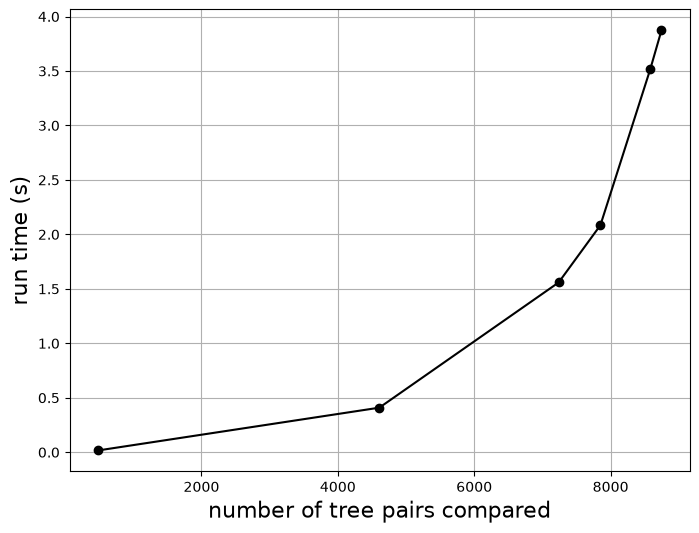

In [30]:
## plot the results w.r.t. number of tree pairs
plt.figure(figsize=(8,6))
plt.plot(_BS['tree pairs'], _BS['runtime'], 'o-', color='black')
plt.grid()
plt.xlabel('number of tree pairs compared', fontsize=16)
plt.ylabel('run time (s)', fontsize=16)
plt.show()


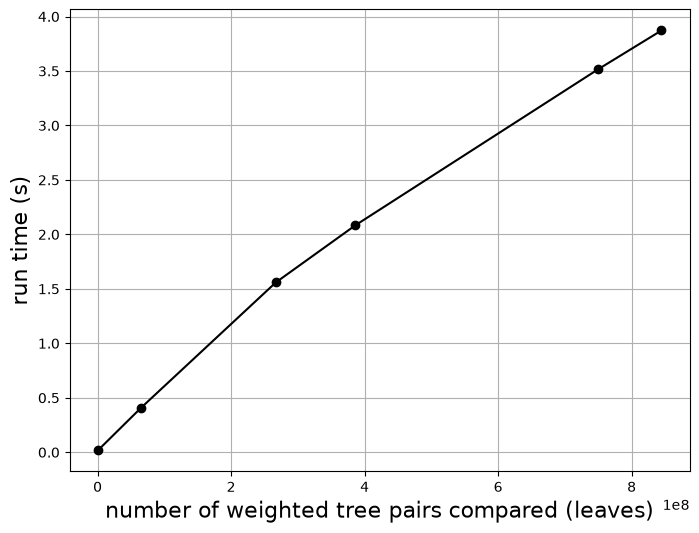

In [31]:
## plot the results w.r.t. number of weighted tree pairs (i.e. product of number of leaves)
plt.figure(figsize=(8,6))
plt.plot(_BS['weighted tree pairs (leaves)'], _BS['runtime'], 'o-', color='black')
plt.grid()
plt.xlabel('number of weighted tree pairs compared (leaves)', fontsize=16)
plt.ylabel('run time (s)', fontsize=16)
#plt.savefig('acme_timing.png')
plt.show()


# Experiment #3 - Classification of root processes

We select subtrees with root process from one of the 6 most common ones: 
```['bash.exe', 'taskhostw.exe', 'cmd.exe', 'smss.exe', 'setup.exe', 'powershell.exe']```

- we first use a **random set** of trees as templates
- we then force a **minimum number of template trees** for each common process
- we use the fast implementation with default weights
- TODO: exclude the root itself from the scoring (as it induces bias)


In [32]:
## top-6 root process names
n_class = 6
_df = df_trees[(df_trees.nodes<=5000) & (df_trees.layers>=3)]
common_proc = [x[0] for x in Counter(_df.process).most_common(n_class)]
_df = _df[_df.process.isin(common_proc)]
_df = _df.reset_index()
print(Counter(_df.process))


Counter({'bash.exe': 507, 'taskhostw.exe': 486, 'cmd.exe': 264, 'smss.exe': 186, 'setup.exe': 111, 'powershell.exe': 106})


In [33]:
def generate_bool_vector(n_true, n_false):
  vector = [True] * n_true + [False] * n_false
  random.shuffle(vector)
  return np.array(vector)

##### Uncomment the two cells below to run - it takes a few minutes, saving a pkl file for quick reference


In [34]:
with open("Data/exp3.pkl", "rb") as fp:
    _results = pickle.load(fp)
_results = _results[_results['min']<4] ## drop those, makes nicer plots


### experiment #3(a) -- increasing number of random templates


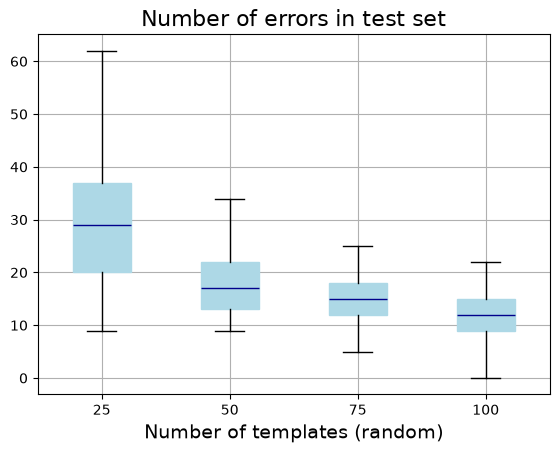

In [35]:
props = dict(boxes="lightblue", whiskers="black", medians="DarkBlue", caps="black")
_results[_results['min']==0].boxplot(column='errors', by='templates', showfliers=False, color=props, patch_artist=True)
plt.suptitle('')
plt.title('Number of errors in test set', fontsize=16)
plt.xlabel('Number of templates (random)', fontsize=14);
#plt.savefig('acme_classify_random.png')


### experiment #3(b) -- small set of templates with minimal class representation

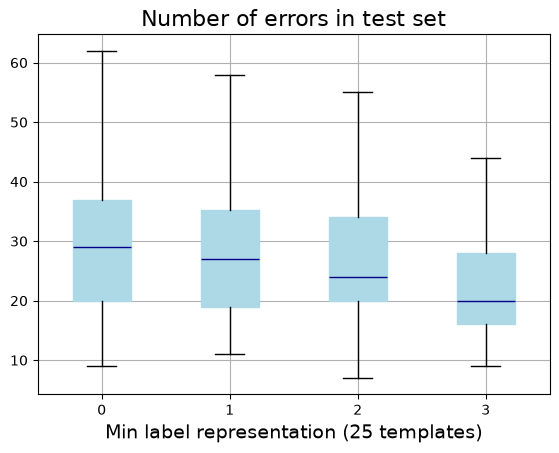

In [36]:
props = dict(boxes="lightblue", whiskers="black", medians="DarkBlue", caps="black")
_results[_results['templates']==25].boxplot(column='errors', by='min', showfliers=False, color=props, patch_artist=True)
plt.suptitle('')
plt.title('Number of errors in test set', fontsize=16)
plt.xlabel('Min label representation (25 templates)', fontsize=14);
#plt.savefig('acme_classify_minrep.png')


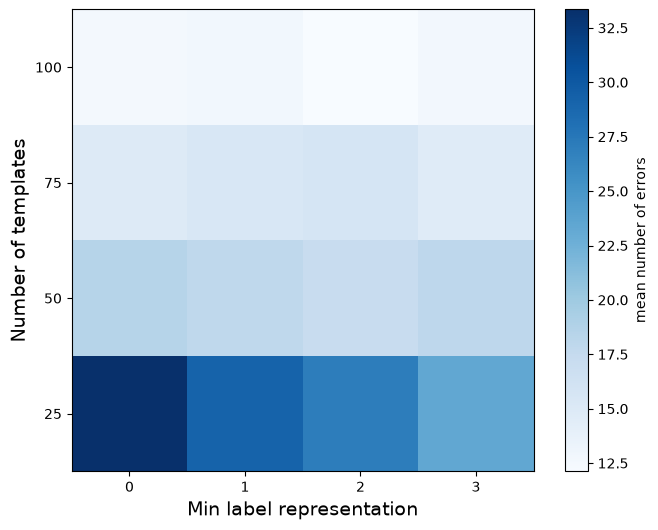

In [37]:
## plotting every combination
grille = np.array(_results.groupby(by=['templates','min']).mean(['errors'])).reshape(4,4)
plt.figure(figsize=(8, 6))
im = plt.imshow(grille, cmap='Blues', origin='lower')
plt.yticks(range(4), [25,50,75,100])
plt.xticks(range(4), [0,1,2,3])
plt.colorbar(im, label='mean number of errors')
plt.xlabel('Min label representation', fontsize=14)
plt.ylabel('Number of templates', fontsize=14)
#plt.savefig('acme_classify_all.png')
plt.show() 


# Experiment #4 - Embedding/Clustering

* We use the same data as in the previous experiment (subtrees with root process from a list of common ones).
* We use 100 random template trees
* For every other tree, we build a vector (embedding) from its matching similarty score using the embedded weights (experiment #1(d), ecdf embedding of the PIDs)


In [38]:
## init
random.seed(42)
n_templates = 100
is_template = generate_bool_vector(n_templates, _df.shape[0]-n_templates)
templates = np.where(is_template==True)[0].tolist()
others = np.where(is_template==False)[0].tolist()
Score = np.zeros(shape=(len(templates), len(others)))

## embedding weights
dim = len(next(iter(embedding_ecdf.values())))
def _es(a, b, _process, _emb):
    return int(_process[a]==_process[b])*(1-distance.cityblock(_emb[a],_emb[b])/dim)
weight = partial(_es, _process=dct_processname, _emb=embedding_ecdf)

## preprocessing
TreeData = []
T = list(_df.tree)
R = list(_df.root)
for i in range(len(T)):
    sg = acme_get_bfs_subtree(Trees, T[i], R[i])
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='uid')) ## need 'uid' in weight function

## matching algorithm
for i in range(len(templates)):
    for j in range(len(others)):
        match = nwt.align_trees_algorithm1(TreeData[templates[i]], TreeData[others[j]], w=weight)
        Score[i,j] = match.score

## ground truth
GT = []
for i in others:
    v = Trees.subgraph(T[i]).vs[R[i]]
    GT.append(v['process'])
GroundTruth = np.array(GT)


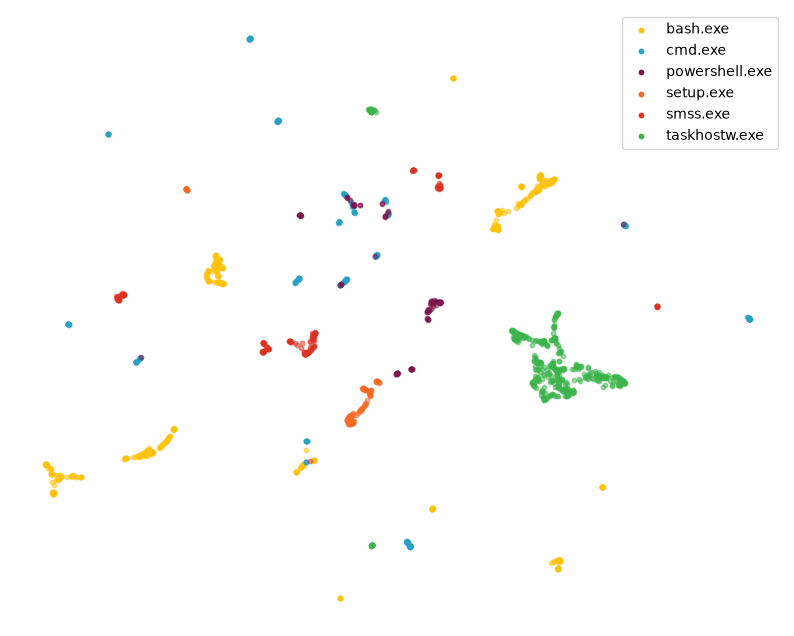

In [39]:
## Embedding
scaler = StandardScaler()
X = scaler.fit_transform( (Score).T )

## 2D mapping
reducer = umap.UMAP(n_neighbors=11, init='random', metric='euclidean', random_state=123, n_jobs=1)
embedding = reducer.fit_transform(X)

# Plot - color w.r.t. GT
plt.figure(figsize=(10,8))
_dct = {v:k for k,v in enumerate(sorted(set(GT)))}
colors = ['#FFC20A','#28A1C7','#801650','#F46A25','#DC3220','#3cb44b']    
for c, l in enumerate(_dct):
    plt.scatter(embedding[GroundTruth==l, 0], embedding[GroundTruth==l, 1], s=10, c=colors[c], label=l, alpha=.5)
#plt.title('Embedding process trees with common root process')
leg = plt.legend()
for handle in leg.legend_handles:
    handle.set_alpha(1.0)
plt.tick_params(axis='both', which='both', bottom=False, top=False, left=False, right=False, labelbottom=False, labelleft=False)
plt.axis('off')
#plt.savefig('acme_embed.png', bbox_inches='tight', pad_inches=0)
plt.show()


### A few quick clustering results from the above

* HDBSCAN with default parameters, then after some trials, with better parameters
* ECG on KNN graph calibrated to get similar number of clusters as HDBSCAN


In [40]:
## HDBSCAN default
clusterer = HDBSCAN(copy=False)
labels = clusterer.fit_predict(X)
b = (labels>=0)
print('refuse to cluster:',sum(labels==-1),'; number of clusters:',max(labels)+1,'; AMI on clustered points:',AMI(GroundTruth[b], labels[b]))

## HDBSCAN better 
clusterer = HDBSCAN(copy=False, min_cluster_size=25, metric='manhattan', min_samples=1)
labels = clusterer.fit_predict(X)
b = (labels>=0)
print('refuse to cluster:',sum(labels==-1),'; number of clusters:',max(labels)+1,'; AMI on clustered points:',AMI(GroundTruth[b], labels[b]))


refuse to cluster: 520 ; number of clusters: 73 ; AMI on clustered points: 0.5506512220317787
refuse to cluster: 123 ; number of clusters: 16 ; AMI on clustered points: 0.7746530618962448


In [41]:
# Knn graph
knn = NearestNeighbors(n_neighbors=9, metric='minkowski', p=1)
knn.fit(X)
K = knn.kneighbors(X)[1]
_dict = {i: row for i, row in enumerate(K)}
G = ig.Graph.ListDict(_dict, )
G = G.simplify()
G.vs['label'] = [str(i) for i in GroundTruth] 

# ECG clusters
np.random.seed(42)
random.seed(42)
GCC = G.community_ecg(ens_size=32, resolution=.01, final='leiden') ## calibrated to get similar number of clusters as HDBSCAN
G.es['W'] = GCC.W
print(GCC.summary())
print('AMI:',AMI(GCC.membership, G.vs['label']))


Clustering with 1560 elements and 16 clusters
AMI: 0.7658281971109454


# Experiment #5 - Filepaths

Several PIDs are associated to one or several files, for which we have the entire filepaths.
We can view a filepath as a directed path, or directed tree, where each node is a directory or a filename (final node).
Almost all filepaths start with ```C:``` which we ignore when building the directed paths.

As expected, many filepaths appear often (ex: frequent Windows dll's), and several pairs of filepath differ only in one position (ex: different user directory).
After some EDA, we ...

The data table can be found here: ```https://gdo168.llnl.gov/data/ACME4/stdview-20240819-20240923```


In [42]:
## the data table
df_files = pd.read_parquet("Data/process_file.parquet", columns=['pid_hash', 'process_name', 'filename'])

### EDA


In [43]:
## all filepaths
print(df_files.shape[0],'filepaths')
## unique filepaths
print(len(set(df_files.filename)),'unique filepaths')

## split, look at first element and drop, save
S = [f.split('\\') for f in df_files.filename]
print('first item:',Counter([s[0] for s in S]))
S = [s[1:] for s in S] ## drop leading c:
df_files['path'] = S
df_files['length'] = [len(s) for s in S]
print('filepath length range:', min(df_files.length), max(df_files.length))
df_files.head(5)


9343199 filepaths
2653580 unique filepaths
first item: Counter({'c:': 9340451, '': 2742, 'd:': 3, 'e:': 2, 'f:': 1})
filepath length range: 1 23


,pid_hash,process_name,filename,path,length
0,6807D0BE6243F8A5D72EC3123D43EADA,ntoskrnl.exe,c:\windows\system32\samcli.dll,"[windows, system32, samcli.dll]",3
1,6807D0BE6243F8A5D72EC3123D43EADA,ntoskrnl.exe,c:\windows\temp,"[windows, temp]",2
2,6807D0BE6243F8A5D72EC3123D43EADA,ntoskrnl.exe,c:\programdata\wintap\logs\wintap.log,"[programdata, wintap, logs, wintap.log]",4
3,B696A80670588C5193175908523F8068,ntoskrnl.exe,c:\$logfile,[$logfile],1
4,FC2EC18B2ECC85580CFD8287B0A85E5A,mergehelper.exe,c:\program files\dotnet\shared\microsoft.netco...,"[program files, dotnet, shared, microsoft.netc...",6


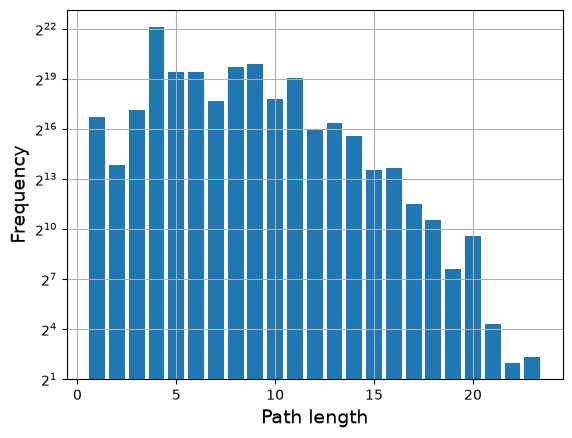

In [44]:
## path length distribution
counts = Counter(df_files['length'])
labels, values = zip(*counts.items())
plt.bar(labels, values, )
#plt.title("Path length distribution")
plt.xlabel("Path length", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.yscale('log', base=2)
plt.grid()
#plt.savefig('files_lengths.png')
plt.show()


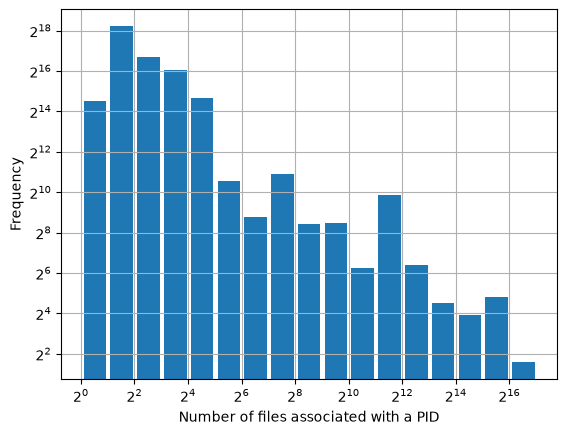

In [45]:
## Number of files associated with PID's (having 1+ files)
X = list(Counter(df_files.pid_hash).values())
bins = 2**(np.arange(0,18))
plt.hist(X, bins=bins,  rwidth=.85)
plt.xscale('log', base=2)
plt.yscale('log', base=2)
plt.xlabel('Number of files associated with a PID')
plt.ylabel('Frequency')
plt.grid()
#plt.savefig('files_number.png')
plt.show()

In [46]:
## drop length 1 paths for the experiments
df_files = df_files[df_files.length>1]
df_files = df_files.reset_index()


### experiment #5(a) -- Examples of matches given a specific users and filename

There are many distinct paths, and many partial matches between paths.

To limit our search, we consider
* paths of a given length only
* 1-off matches only
* specific usernames and filename


In [47]:
## very limited list 
_ = [x for x in df_files[df_files.length==7]['path']]
S = [x for x in _ if ( ( (x[1]=='user1') or (x[1]=='baduser3') ) and (x[6]=='cv_debug.log') )]

## encode all trees
TreeData = []
for s in S:
    sg = ig.Graph.TupleList([(i,i+1) for i in range(len(s)-1)], directed=True)
    sg.vs['dir'] = s
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='dir'))
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## matches
_results = []
users = np.array([s[1] for s in S ])
for i in np.where(np.array(users)=='user1')[0]:
    for j in np.where(np.array(users)=='baduser3')[0]:
        _, score = fast.predict_encoded(enc[i], enc[j])
        if score == 6:
            _results.extend(['/'.join(S[i]), '/'.join(S[j])])
set(_results)

{'users/baduser3/appdata/local/temp/3/cv_debug.log',
 'users/baduser3/appdata/local/temp/4/cv_debug.log',
 'users/baduser3/appdata/local/temp/6/cv_debug.log',
 'users/user1/appdata/local/temp/3/cv_debug.log',
 'users/user1/appdata/local/temp/4/cv_debug.log',
 'users/user1/appdata/local/temp/6/cv_debug.log'}

### experiment #5(b) -- Matching all filepaths from a chosen redteam PID

* we select a PID from ```baduser3``` with around 60 filepaths and set those as our templates
* we list all non-redteam PIDs with similar number of filepaths as candidates
* for each template file, find best match for each candidate ; store only if best match is of size at least 3 (avoid very short matches) 
* for every match, normalize the score dividing by the template's length


In [48]:
## example where username == baduser3
badfiles = df_files[df_files['pid_hash'] == 'BB8D51837C4CD278B09A83D92341D00B']['path'].tolist()
print('number of files for redteam PID:',len(badfiles))

## pick non-redteam candidates with similar number of files
_ctr = Counter(df_files['pid_hash'])
candidates = [k for k, c in _ctr.items() if ( (55 <= c <= 65) and (dct_label.get(k,-1)==0))]
print('number of candidate PIDs:',len(candidates))
candidate_paths = []
for c in candidates:
    c_files = df_files[df_files['pid_hash'] == c]['path'].tolist()
    candidate_paths.append( (c,c_files) )  


number of files for redteam PID: 59
number of candidate PIDs: 90


In [49]:
## pre-processing
TreeData = []
for s in badfiles:
    sg = ig.Graph.TupleList([(i,i+1) for i in range(len(s)-1)], directed=True)
    sg.vs['dir'] = s
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='dir'))
for (h,c) in candidate_paths:
    for s in c:
        sg = ig.Graph.TupleList([(i,i+1) for i in range(len(s)-1)], directed=True)
        sg.vs['dir'] = s
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='dir'))    

## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## compare all candidates' files with every template files
L = []
lens = [len(x[1]) for x in candidate_paths]
for i in range(len(badfiles)):
    gap = len(badfiles)
    for c in range(len(candidate_paths)):
        max_score = 0
        for j in range(lens[c]):
            _, score = fast.predict_encoded(enc[i], enc[j+gap])
            if score>max_score:
                max_score = score
        gap += lens[c]
        if max_score>=3:
            L.append([i,c,int(max_score),len(badfiles[i])])
df_pid = pd.DataFrame(L, columns=['badfile','candidate','score','max_score'])
df_pid['ratio'] = df_pid['score'] / df_pid['max_score']


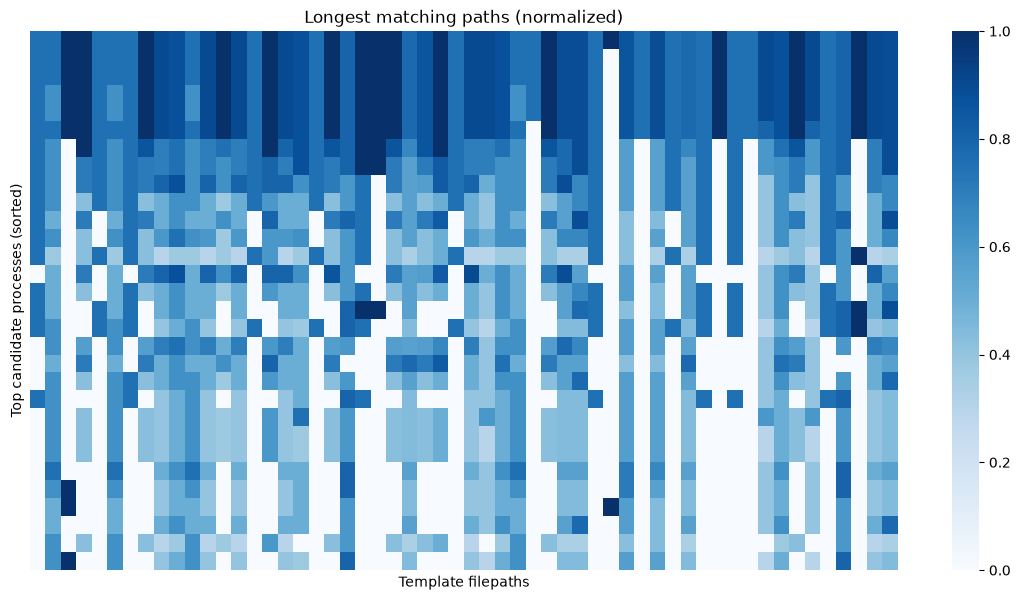

In [50]:
## pivot the df
pivot_df = df_pid.pivot_table(index="candidate", columns="badfile", values="ratio", fill_value=0)
_s = df_pid.groupby(by='candidate').sum()['ratio'].sort_values(ascending=False).index.tolist()
pivot_df = pivot_df.reindex(_s)
# create the heatmap
plt.figure(figsize=(14, 7))
sns.heatmap(pivot_df[:30], cmap="Blues", annot=False)
# add labels and display
plt.xlabel("Template filepaths")
plt.ylabel("Top candidate processes (sorted)")
plt.title("Longest matching paths (normalized)")
plt.xticks([], [])
plt.yticks([], [])
#plt.savefig('files_top.png')
plt.show()


In [51]:
## who are the top candidates?
l = [candidates[i] for i in pivot_df.index[:6]]+['BB8D51837C4CD278B09A83D92341D00B']
process_summary[process_summary['pid_hash'].isin(l)][['pid_hash','red_team','user_name','process_name']]


,pid_hash,red_team,user_name,process_name
1575,BB8D51837C4CD278B09A83D92341D00B,1,ACME\baduser3,explorer.exe
207105,D6F14DA9BF7A140A0C517A8F844EDCA5,0,ACME\user9,explorer.exe
208006,6A7D0BB4BDFE020D8002E7B1DD63119C,0,ACME\user3,explorer.exe
258722,1E573773CE225C0086445E464B30FA83,0,ACME\user1,explorer.exe
558245,64E918B0B8816AA13027EC8F82A80C12,0,ACME\user9,explorer.exe
1246684,E5F28611DE62911DBF2231B3281D8DF8,0,ACME\user3,explorer.exe
1534115,A282FBBB927044F99CA48E7F8445A5A6,0,ACME\user9,explorer.exe


In [52]:
## this filepath has mostly 0-score (column mostly while in above plot) ... rare file
print(badfiles[39])
print('frequency:', sum([x[-1:][0]=='uiautomationcore.dll' for x in df_files.path]))


['windows', 'system32', 'uiautomationcore.dll']
frequency: 371


### experiment #5(c) -- Timings

Filepaths are special trees each with a single path. There is still some 3x speedup with the fast algorithm nevertheless.
    

In [53]:
## every path of length 7
_ = [x for x in df_files[df_files.length==7]['path']]

## encode all trees
TreeData = []
for s in _:
    sg = ig.Graph.TupleList([(i,i+1) for i in range(len(s)-1)], directed=True)
    sg.vs['dir'] = s
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='dir'))
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]


In [54]:
## compare N x N paths with fast & slow algorithm
L = []
for N in np.linspace(100,1000,10,dtype='int'):
    _r = random.sample( range(len(enc)), 2*N)
    a = time.time()
    for i in _r[:N]:
        for j in _r[-N:]:
            _, score = fast.predict_encoded(enc[i], enc[j])
    t_fast = time.time()-a
    a = time.time()
    for i in _r[:N]:
        for j in _r[-N:]:
            match = nwt.align_trees_algorithm1(TreeData[i],TreeData[j])  
    t_slow = time.time()-a
    L.append([N*N, t_fast, t_slow])


ratio:
 [2.4821761248175878, 2.6683925420547356, 2.886324359962292, 2.841304172411017, 2.699787432191851, 2.692659688427998, 2.8384346007933785, 2.58838694613802, 2.789312625330949, 2.7242287183871174]


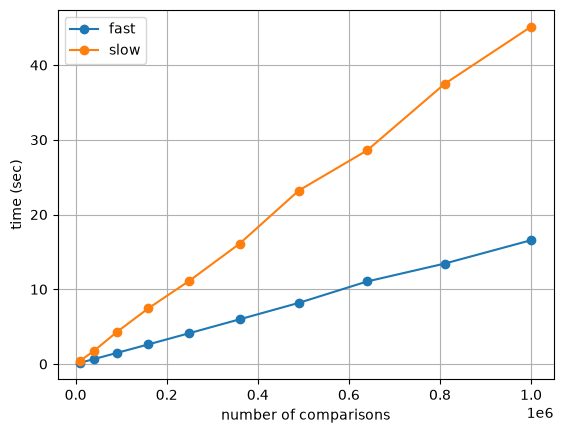

In [55]:
_df = pd.DataFrame(L, columns=['tests','fast','slow'])
plt.plot(_df.tests, _df.fast, 'o-', label='fast')
plt.plot(_df.tests, _df.slow, 'o-', label='slow')
plt.grid()
plt.xlabel('number of comparisons')
plt.legend()
plt.ylabel('time (sec)');
print('ratio:\n',list(_df.slow/_df.fast))